[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 4 — Pile](theme4_pile.ipynb) · [Thème 6 — Préfixes, dichotomie, tri](theme6_prefixes_dichotomie_tri.ipynb) ➡

# Thème 5 — Explorer une grille ou un graphe : BFS et DFS

**Dans ce notebook, tu vas apprendre :**
- ce qu'est un graphe, et pourquoi une grille en est un ;
- ce qu'est une file, et la différence avec une pile ;
- comment fonctionnent BFS et DFS, et lequel choisir ;
- compter des zones connectées et trouver un plus court chemin.

**Prérequis :** thèmes 1, 2 et 4 (set, grilles, pile)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Le problème de départ
> Un labyrinthe est une grille : `0` = case libre, `1` = mur. On part en haut à gauche et on veut aller en bas à droite, en se déplaçant haut / bas / gauche / droite. **Quel est le nombre minimum de pas ?**

Essayer des chemins « au hasard » ne marche pas : on oublie des cases, on repasse dix fois au même endroit, on tourne en rond. Il faut une **exploration systématique**. Il en existe deux grandes : **BFS** et **DFS**.
Pour les comprendre, il faut d'abord deux notions : le **graphe** et la **file**.

## Concept 1 : le graphe
Un **graphe**, ce sont des **points** (appelés *nœuds*) reliés par des **liens** (appelés *arêtes*). Exemples : des villes reliées par des routes, des personnes reliées par des amitiés.

**Une grille est un graphe** : chaque case libre est un nœud, reliée à ses voisines haut / bas / gauche / droite (thème 2).

En Python, on représente souvent un graphe par un **dict** : chaque nœud → la liste de ses voisins. On appelle ça une *liste d'adjacence*.

Voici le graphe qui sert d'exemple dans tout le notebook : 6 nœuds (A à F) et 6 arêtes.

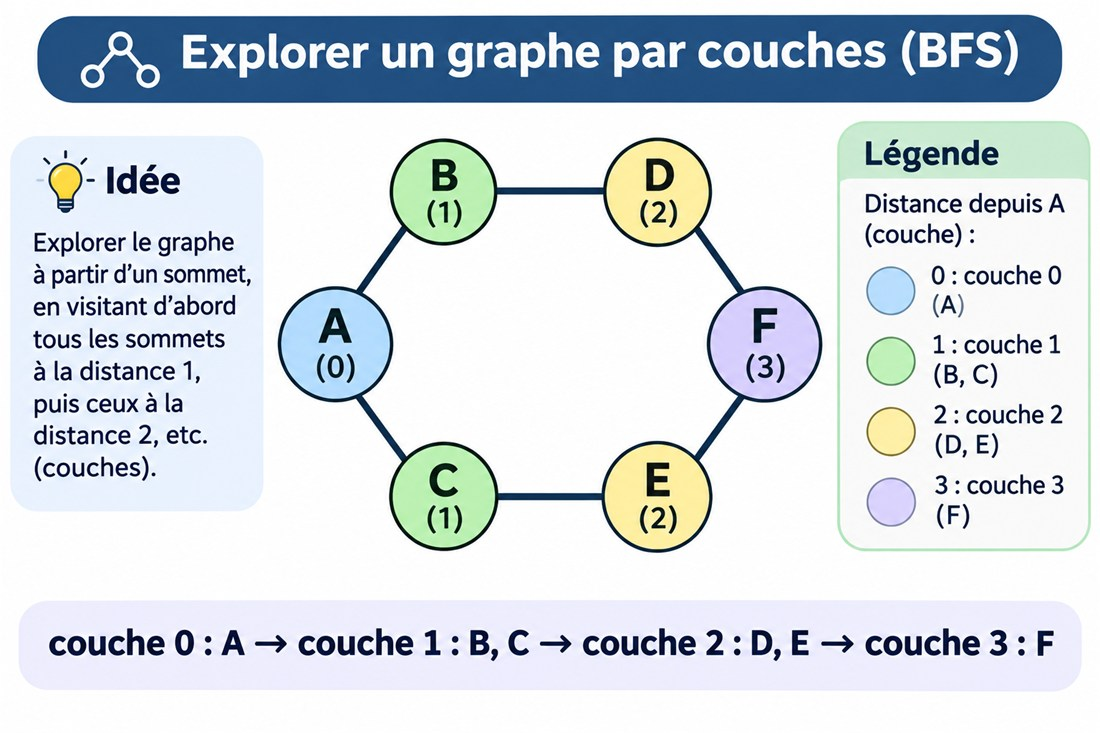

Il y a deux chemins de A à F : par le haut (A, B, D, F) et par le bas (A, C, E, F). Les couleurs donnent la **distance** depuis A (le nombre de liens à traverser) : c'est exactement ce que le BFS calculera plus bas. Sur l'image, « sommet » est un autre mot pour « nœud » (rien à voir avec le sommet d'une pile).

In [ ]:
# Le graphe de l'image, écrit en Python
graphe = {
    "A": ["B", "C"],
    "B": ["A", "D"],
    "C": ["A", "E"],
    "D": ["B", "F"],
    "E": ["C", "F"],
    "F": ["D", "E"],
}
print("Voisins de A :", graphe["A"])
print("Voisins de D :", graphe["D"])

## Concept 2 : la file (queue), l'inverse de la pile
Une **file**, c'est la file d'attente à la boulangerie : on arrive **à la fin**, on est servi **par le début**. Le premier arrivé est le premier sorti (*FIFO : First In, First Out*).

| | Pile (thème 4) | File |
|---|---|---|
| On ajoute | au sommet | à la fin |
| On retire | **le plus récent** | **le plus ancien** |
| En Python | `list` : `append` / `pop()` | `deque` : `append` / `popleft()` |

Pourquoi `deque` plutôt qu'une liste avec `pop(0)` ? Retirer le premier élément d'une liste oblige Python à **décaler tous les autres** d'une case : O(n) à chaque fois. `deque` (*double-ended queue*) retire au début en O(1).

In [ ]:
from collections import deque

file = deque()
file.append("A")
file.append("B")
file.append("C")
print(file)              # deque(['A', 'B', 'C'])
print(file.popleft())    # A — le premier arrivé sort en premier
print(file)              # deque(['B', 'C'])

## BFS — explorer par couches (*Breadth-First Search*, « parcours en largeur »)

### L'idée
Image mentale : un **caillou jeté dans l'eau**. L'onde touche d'abord tout ce qui est à distance 1, puis tout ce qui est à distance 2, puis 3… BFS explore exactement ainsi : d'abord les voisins du départ, puis les voisins des voisins, etc.

### L'algorithme
1. Mettre le départ dans la file et le marquer comme **visité**.
2. Tant que la file n'est pas vide :
   - retirer le **premier** nœud de la file ;
   - pour chacun de ses voisins **pas encore visité** : le marquer visité et l'ajouter **à la fin** de la file.

Le set `visites` est indispensable : sans lui, A envoie vers B, B renvoie vers A, A renvoie vers B… boucle infinie.

### Trace à la main sur le graphe, depuis A
| Étape | On retire | Voisins non visités → ajoutés | File après | Visités |
|---|---|---|---|---|
| 0 | — | (départ) | A | A |
| 1 | A | B, C | B, C | A B C |
| 2 | B | D (A déjà vu) | C, D | A B C D |
| 3 | C | E (A déjà vu) | D, E | A B C D E |
| 4 | D | F (B déjà vu) | E, F | A B C D E F |
| 5 | E | — (C et F déjà vus) | F | idem |
| 6 | F | — | *(vide)* | idem |

Ordre de visite : A, puis **B, C** (distance 1), puis **D, E** (distance 2), puis **F** (distance 3) : ce sont les couches de l'onde, et les couleurs de l'image du graphe.

In [ ]:
from collections import deque

def bfs(graphe, depart):
    visites = {depart}
    file = deque([depart])
    distance = {depart: 0}        # à combien de pas du départ se trouve chaque nœud
    ordre = []

    while file:                   # tant que la file n'est pas vide
        noeud = file.popleft()    # le plus ancien arrivé
        ordre.append(noeud)
        for voisin in graphe[noeud]:
            if voisin not in visites:
                visites.add(voisin)                     # marqué DÈS qu'on l'ajoute à la file
                distance[voisin] = distance[noeud] + 1  # un pas de plus que le nœud actuel
                file.append(voisin)
    return ordre, distance

ordre, distance = bfs(graphe, "A")
print("Ordre de visite     :", ordre)
print("Distances depuis A  :", distance)

### Pourquoi BFS trouve le plus court chemin
BFS traite **tous** les nœuds à distance 1 avant ceux à distance 2, et ainsi de suite. Donc **la première fois qu'il atteint un nœud, c'est forcément par un plus court chemin**. C'est valable quand tous les pas « coûtent » la même chose (on dit : graphe **sans poids**). Si les liens ont des coûts différents (des routes de longueurs différentes), il faut un autre algorithme (Dijkstra), hors programme ici.

### Pourquoi marquer « visité » au moment d'**ajouter** à la file ?
Si on attendait le moment de le retirer, un même nœud pourrait être ajouté plusieurs fois par différents voisins (ici, F serait ajouté par D **et** par E). Le résultat resterait correct, mais avec du travail en double — et sur une grande grille, beaucoup de travail en double.

## DFS — aller au bout avant de revenir (*Depth-First Search*, « parcours en profondeur »)

### L'idée
Image mentale : explorer un labyrinthe en gardant une main sur le mur. On avance **le plus loin possible** ; quand on est bloqué, on **revient en arrière** jusqu'au dernier embranchement et on essaie une autre direction.

### Le seul vrai changement par rapport à BFS
On remplace la **file** par une **pile** : on reprend toujours le nœud **le plus récent**, donc on s'enfonce.

In [ ]:
def dfs(graphe, depart):
    visites = set()
    pile = [depart]
    ordre = []

    while pile:
        noeud = pile.pop()             # le PLUS RÉCENT : c'est la différence avec BFS
        if noeud in visites:
            continue                   # déjà exploré par un autre chemin
        visites.add(noeud)
        ordre.append(noeud)
        for voisin in graphe[noeud]:
            if voisin not in visites:
                pile.append(voisin)
    return ordre

print("DFS depuis A :", dfs(graphe, "A"))   # A → C → E → F → D → B : on s'enfonce d'un côté

Remarque : avec une pile, un même nœud peut être empilé deux fois avant d'être exploré (ici B). Le `if noeud in visites: continue` évite de le traiter deux fois.

### DFS en version récursive
Une fonction **récursive** est une fonction qui s'appelle elle-même. Ici : « explorer un nœud » = le marquer, puis **explorer chacun de ses voisins non visités**. Quand l'exploration d'un voisin est finie, Python revient tout seul là où il en était et passe au voisin suivant — c'est le « retour en arrière ».

In [ ]:
def dfs_recursif(graphe, noeud, visites, ordre):
    visites.add(noeud)
    ordre.append(noeud)
    for voisin in graphe[noeud]:
        if voisin not in visites:
            dfs_recursif(graphe, voisin, visites, ordre)   # on s'enfonce ; au retour, voisin suivant
    return ordre

print("DFS récursif depuis A :", dfs_recursif(graphe, "A", set(), []))

Pour se souvenir « où il en était », Python utilise en coulisses… une pile (la *pile d'appels*). Elle est limitée à environ **1 000 appels imbriqués** : au-delà, `RecursionError`. Sur une grande grille (100 × 100 = 10 000 cases), préfère la version avec une pile explicite.

### Attention : DFS ne donne PAS le plus court chemin
Dans ce petit graphe, D est **directement** relié à A. Mais DFS peut l'atteindre par le long chemin A → B → C → D :

In [ ]:
petit_graphe = {
    "A": ["D", "B"],
    "B": ["A", "C"],
    "C": ["B", "D"],
    "D": ["C", "A"],
}
print("Ordre DFS :", dfs(petit_graphe, "A"))           # A, B, C, D : D est atteint en dernier, via C
print("Distances BFS :", bfs(petit_graphe, "A")[1])    # D est à distance 1

### BFS ou DFS ?
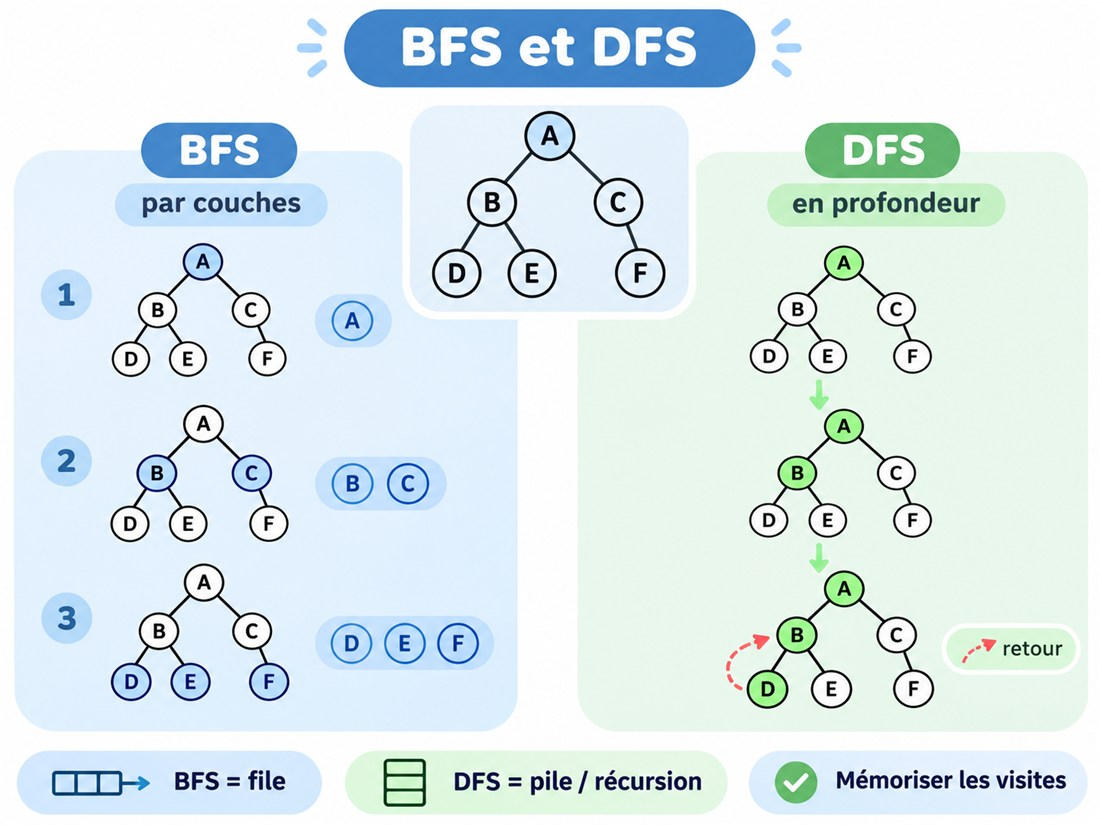

L'image résume les deux parcours sur un petit arbre :
- **BFS** (à gauche) visite par couches : A, puis B et C, puis D, E et F. Il utilise une **file**.
- **DFS** (à droite) s'enfonce : A → B → D, puis **revient en arrière** (« retour ») vers B pour explorer E, puis remonte jusqu'à A pour explorer C et F. Il utilise une **pile** ou la récursion. C'est l'ordre de `dfs_recursif` ; la version avec une pile explicite part d'abord à droite (C), car elle reprend le dernier voisin empilé : même principe, autre côté.
- Dans les deux cas, on **mémorise les nœuds visités**.

| Ce que demande l'énoncé | Choix |
|---|---|
| « plus court chemin », « nombre minimum de pas / coups » | **BFS** (obligatoire) |
| « combien de zones / îles / groupes ? » | les deux marchent ; DFS souvent plus court à écrire |
| « peut-on atteindre… ? » | les deux marchent |
| « tous les chemins possibles », essais avec retour en arrière | **DFS** |

## Application 1 — compter les îles (zones connectées)
> Grille de `1` (terre) et de `0` (eau). Une île est un groupe de terres reliées horizontalement ou verticalement. Combien y a-t-il d'îles ?

**Idée** : on parcourt la grille case par case (double boucle du thème 2). Dès qu'on tombe sur une terre **pas encore visitée**, c'est le début d'une **nouvelle île** : on compte +1, puis on lance une exploration depuis cette case pour **marquer toute l'île** comme visitée. Ainsi, les autres cases de cette île ne seront pas recomptées.

On retrouve tous les outils précédents : les directions et les bornes (thème 2), une pile (thème 4), un set de tuples `(i, j)` (thème 1).

In [ ]:
def nombre_iles(grille):
    if not grille or not grille[0]:
        return 0
    lignes, colonnes = len(grille), len(grille[0])
    visites = set()
    iles = 0

    for i in range(lignes):
        for j in range(colonnes):
            if grille[i][j] == 1 and (i, j) not in visites:
                iles += 1                          # terre jamais vue → nouvelle île
                # DFS avec une pile : on marque toutes les cases de cette île
                pile = [(i, j)]
                visites.add((i, j))
                while pile:
                    ci, cj = pile.pop()
                    for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                        ni, nj = ci + di, cj + dj
                        if (0 <= ni < lignes and 0 <= nj < colonnes
                                and grille[ni][nj] == 1 and (ni, nj) not in visites):
                            visites.add((ni, nj))
                            pile.append((ni, nj))
    return iles

carte = [
    [1, 1, 0, 0, 0],
    [1, 1, 0, 0, 1],
    [0, 0, 0, 1, 1],
    [0, 0, 0, 0, 0],
    [1, 0, 1, 0, 1],
]
print(nombre_iles(carte))   # 5 : le carré en haut à gauche, le « L » à droite, et 3 îlots en bas

## Application 2 — le plus court chemin dans le labyrinthe (le problème de départ)
C'est un BFS sur une grille. Chaque élément de la file est un triplet `(ligne, colonne, nombre de pas pour y arriver)`.

In [ ]:
from collections import deque

def plus_court_chemin(grille):
    # 0 = libre, 1 = mur. Départ en haut à gauche, arrivée en bas à droite.
    if not grille or not grille[0]:
        return -1
    lignes = len(grille)
    colonnes = len(grille[0])

    if grille[0][0] == 1 or grille[lignes - 1][colonnes - 1] == 1:
        return -1                                  # départ ou arrivée muré

    file = deque([(0, 0, 0)])                      # (ligne, colonne, nombre de pas)
    visites = {(0, 0)}

    while file:
        i, j, d = file.popleft()                   # la case en attente la plus proche du départ
        if (i, j) == (lignes - 1, colonnes - 1):
            return d                               # 1re arrivée = chemin le plus court (propriété du BFS)

        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            ni, nj = i + di, j + dj
            if (0 <= ni < lignes and 0 <= nj < colonnes   # dans la grille
                    and grille[ni][nj] == 0                 # pas un mur
                    and (ni, nj) not in visites):           # pas déjà atteinte
                visites.add((ni, nj))
                file.append((ni, nj, d + 1))       # un pas de plus

    return -1                                      # file vide sans atteindre l'arrivée : impossible

grille = [
    [0, 0, 1],
    [1, 0, 1],
    [0, 0, 0],
]
print(plus_court_chemin(grille))              # 4 : (0,0)→(0,1)→(1,1)→(2,1)→(2,2)
print(plus_court_chemin([[0, 1], [1, 0]]))    # -1 : arrivée inaccessible
print(plus_court_chemin([[0]]))               # 0 : on est déjà arrivé

Les distances découvertes par le BFS sur la première grille (`#` = mur) — on voit l'onde se propager :
```
0  1  #
#  2  #
4  3  4
```

**Lien avec le thème 2** : la simulation « contamination » (à chaque tour, les voisins des malades tombent malades) est en fait un BFS ! Chaque couche du BFS correspond à un tour. Pour savoir « en combien de tours tout est contaminé », on lance un BFS depuis **toutes** les cases malades à la fois.

## Quand y penser ?
- « connecté », « relié », « zone », « région », « île », « groupe » ;
- « labyrinthe », « atteindre », « chemin » ;
- « nombre minimum de pas / de mouvements / de transformations » → **BFS** ;
- une propagation sur une grille (contamination, inondation, incendie…) → **BFS**, une couche par tour.

## Les pièges
- Oublier `visites` → boucle infinie.
- Utiliser DFS pour un plus court chemin → réponse trop grande.
- `liste.pop(0)` au lieu de `deque.popleft()` → lent sur les grandes grilles.
- DFS récursif sur une grande grille → `RecursionError`.
- Mettre des listes `[i, j]` dans un set → `TypeError` : utiliser des tuples `(i, j)`.

## À toi de jouer — la plus grande île
> Même grille que `nombre_iles`. Renvoie la **taille** (le nombre de cases) de la plus grande île, ou 0 s'il n'y a pas d'île.

**Indice** : reprends `nombre_iles`. Au lieu de compter les îles, compte les cases retirées de la pile pendant chaque exploration, et garde le maximum.

In [ ]:
def plus_grande_ile(grille):
    # À toi de jouer !
    pass

verifier(plus_grande_ile, [
    ((carte,), 4),
    (([[0, 0], [0, 0]],), 0),
    (([[1]],), 1),
    (([[1, 0, 1], [1, 0, 1], [1, 1, 1]],), 7),   # une île en forme de U
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def plus_grande_ile(grille):
    if not grille or not grille[0]:
        return 0
    lignes, colonnes = len(grille), len(grille[0])
    visites = set()
    meilleure = 0
    for i in range(lignes):
        for j in range(colonnes):
            if grille[i][j] == 1 and (i, j) not in visites:
                taille = 0
                pile = [(i, j)]
                visites.add((i, j))
                while pile:
                    ci, cj = pile.pop()
                    taille += 1                       # une case de plus dans cette île
                    for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                        ni, nj = ci + di, cj + dj
                        if (0 <= ni < lignes and 0 <= nj < colonnes
                                and grille[ni][nj] == 1 and (ni, nj) not in visites):
                            visites.add((ni, nj))
                            pile.append((ni, nj))
                meilleure = max(meilleure, taille)
    return meilleure
```

</details>

---

**Suite :** [Thème 6 — Sommes préfixes, recherche dichotomique et tri](theme6_prefixes_dichotomie_tri.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 4 — Piles et files](exercices/serie4_piles_files.ipynb) (5 exercices : la pile du thème 4 et la file de ce thème), puis [Série 5 — Graphes, BFS et DFS](exercices/serie5_graphes_bfs_dfs.ipynb) (6 exercices avec tests automatiques)